# **🌍 Earthquake Magnitude Prediction**

Earthquakes are natural events that are difficult to predict. In this project, we use historical earthquake data to explore patterns and estimate **Magnitude** based on time, location, and depth.

We compare four Machine Learning models: **Linear Regression**, **Decision Tree**, **Random Forest**, and **Gradient Boosting**.

The goal is to compare their prediction performance using simple Regression methods.

**Data Source**

Dataset: **Significant Earthquakes, 1965–2016**

The dataset contains earthquakes with a magnitude of **5.5 or higher**

Source: **USGS via Kaggle**

Kaggle: https://www.kaggle.com/datasets/usgs/earthquake-database

Reference project by Aman Kharwal:  
https://amanxai.com/2020/11/12/earthquake-prediction-model-with-machine-learning/


**Problem Type**

This is a **Supervised Learning – Regression** problem because **Magnitude** is a numerical value

**Features (x):** Year, Month, Latitude, Longitude, Depth  
**Target (y):** Magnitude

**Data Dictionary**

| Column | Description |
|---|---|
| Date | Date of the earthquake |
| Time | Time of the earthquake |
| Latitude | North / south position |
| Longitude | East / west position |
| Type | Type of seismic event |
| Depth | Depth of the earthquake in km |
| Depth Error | Error in depth measurement |
| Depth Seismic Stations | Stations used for depth measurement |
| Magnitude | Strength of the earthquake |
| Magnitude Type | Type of magnitude measurement |
| Magnitude Error | Error in magnitude measurement |
| Magnitude Seismic Stations | Stations used for magnitude measurement |
| Azimuthal Gap | Gap between seismic stations in degrees |
| Horizontal Distance | Distance to the nearest seismic station |
| Horizontal Error | Error in location measurement |
| Root Mean Square | Average size of seismic travel-time residuals |
| ID | Unique earthquake ID |
| Source | Source of earthquake information |
| Location Source | Source of location information |
| Magnitude Source | Source of magnitude information |
| Status | Review status of the record |


**Import Libraries**

We import libraries for data analysis, charts, and Machine Learning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


**Load the Data**

We load the CSV file and look at the first rows

In [2]:
df = pd.read_csv("database.csv")
df.head()


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


**Exploratory Data Analysis (EDA)**

Let's check the size, columns, missing values, and basic statistics

In [20]:
df.shape, df.columns

((23232, 23),
 Index(['Date', 'Time', 'Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error',
        'Depth Seismic Stations', 'Magnitude', 'Magnitude Type',
        'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap',
        'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'ID',
        'Source', 'Location Source', 'Magnitude Source', 'Status', 'Year',
        'Month'],
       dtype='str'))

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        23412 non-null  str    
 1   Time                        23412 non-null  str    
 2   Latitude                    23412 non-null  float64
 3   Longitude                   23412 non-null  float64
 4   Type                        23412 non-null  str    
 5   Depth                       23412 non-null  float64
 6   Depth Error                 4461 non-null   float64
 7   Depth Seismic Stations      7097 non-null   float64
 8   Magnitude                   23412 non-null  float64
 9   Magnitude Type              23409 non-null  str    
 10  Magnitude Error             327 non-null    float64
 11  Magnitude Seismic Stations  2564 non-null   float64
 12  Azimuthal Gap               7299 non-null   float64
 13  Horizontal Distance         1604 non-null 

In [5]:
df.isnull().sum()

Date                              0
Time                              0
Latitude                          0
Longitude                         0
Type                              0
Depth                             0
Depth Error                   18951
Depth Seismic Stations        16315
Magnitude                         0
Magnitude Type                    3
Magnitude Error               23085
Magnitude Seismic Stations    20848
Azimuthal Gap                 16113
Horizontal Distance           21808
Horizontal Error              22256
Root Mean Square               6060
ID                                0
Source                            0
Location Source                   0
Magnitude Source                  0
Status                            0
dtype: int64

In [6]:
df.describe()

,Latitude,Longitude,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Error,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square
count,23412.000000,23412.000000,23412.000000,4461.000000,7097.000000,23412.000000,327.000000,2564.000000,7299.000000,1604.000000,1156.000000,17352.000000
mean,1.679033,39.639961,70.767911,4.993115,275.364098,5.882531,0.071820,48.944618,44.163532,3.992660,7.662759,1.022784
std,30.113183,125.511959,122.651898,4.875184,162.141631,0.423066,0.051466,62.943106,32.141486,5.377262,10.430396,0.188545
min,-77.080000,-179.997000,-1.100000,0.000000,0.000000,5.500000,0.000000,0.000000,0.000000,0.004505,0.085000,0.000000
25%,-18.653000,-76.349750,14.522500,1.800000,146.000000,5.600000,0.046000,10.000000,24.100000,0.968750,5.300000,0.900000
50%,-3.568500,103.982000,33.000000,3.500000,255.000000,5.700000,0.059000,28.000000,36.000000,2.319500,6.700000,1.000000
75%,26.190750,145.026250,54.000000,6.300000,384.000000,6.000000,0.075500,66.000000,54.000000,4.724500,8.100000,1.130000
max,86.005000,179.998000,700.000000,91.295000,934.000000,9.100000,0.410000,821.000000,360.000000,37.874000,99.000000,3.440000


**Correlation Heatmap**

Let's see the linear relationships between the main numerical columns

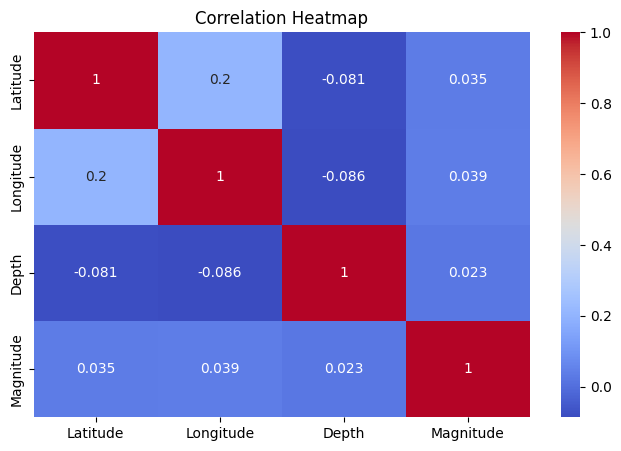

In [7]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[["Latitude", "Longitude", "Depth", "Magnitude"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

`corr()` → Calculates the correlation between variables  
`annot=True` → Shows the correlation values on the heatmap  
`cmap="coolwarm"` → Sets the colors of the heatmap

**Magnitude Distribution**

This plot shows how earthquake magnitudes are distributed


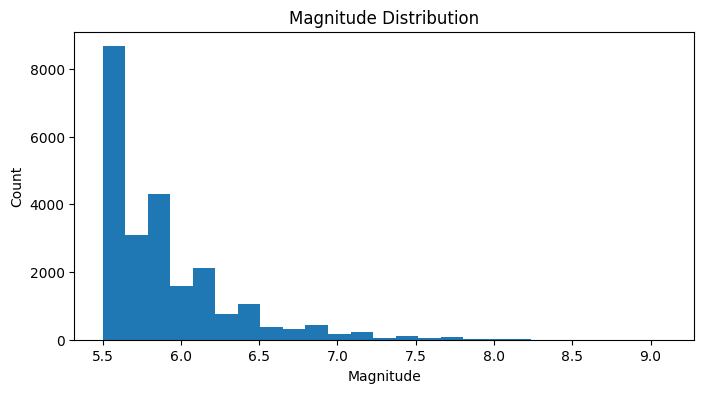

In [8]:
plt.figure(figsize=(8, 4))
plt.hist(df["Magnitude"], bins=25)
plt.title("Magnitude Distribution")
plt.xlabel("Magnitude")
plt.ylabel("Count")
plt.show()


**Earthquake Locations**

Each point represents one earthquake. The color shows its magnitude

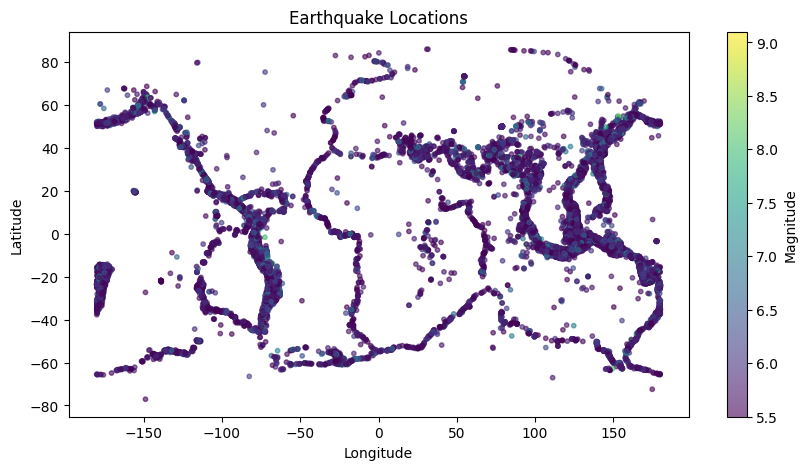

In [9]:
plt.figure(figsize=(10, 5))
plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Magnitude"],
    s=10,
    alpha=0.6
)
plt.colorbar(label="Magnitude")
plt.title("Earthquake Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


**Data Preparation**

We keep earthquake records only and create **Year** and **Month** from the date. The selected model columns have no missing values

In [10]:
df = df[df["Type"] == "Earthquake"].copy()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce", format="mixed", utc=True)
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

print(df[["Year", "Month", "Latitude", "Longitude", "Depth", "Magnitude"]].isnull().sum())

Year         0
Month        0
Latitude     0
Longitude    0
Depth        0
Magnitude    0
dtype: int64


**Features and Target**

**x** contains our input features. **y** is the magnitude we want to predict

In [11]:
features = ["Year", "Month", "Latitude", "Longitude", "Depth"]

x = df[features]
y = df["Magnitude"]


**Train and Test Split**

We use 80% of the data for training and 20% for testing


In [12]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

print("Train:", x_train.shape)
print("Test:", x_test.shape)


Train: (18585, 5)
Test: (4647, 5)


**Linear Regression**

A simple baseline model to compare with the tree-based models


In [13]:
lr = LinearRegression()
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_test)


**Decision Tree Regressor**

A Decision Tree learns simple rules from the data


In [14]:
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(x_train, y_train)
dt_pred = dt.predict(x_test)


**Random Forest Regressor**

Random Forest combines many decision trees to make predictions


In [15]:
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_test)


**Gradient Boosting Regressor**

Gradient Boosting builds trees step by step to improve predictions


In [16]:
gbr = GradientBoostingRegressor(random_state=42)

gbr.fit(x_train, y_train)

gbr_pred = gbr.predict(x_test)


**Model Evaluation**

**MAE** → average prediction error  
**RMSE** → gives more weight to large errors  
**R²** → shows how much variation the model explains

**Model Comparison**

We compare all four models using the same test data


In [17]:
predictions = {
    "Linear Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gbr_pred
}

results = pd.DataFrame({
    name: {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    }
    for name, pred in predictions.items()
}).T

results.round(3)


,MAE,RMSE,R2
Linear Regression,0.314,0.422,0.004
Decision Tree,0.303,0.413,0.047
Random Forest,0.300,0.410,0.062
Gradient Boosting,0.301,0.410,0.058


**Actual vs Predicted**

Points closer to the diagonal line are better predictions


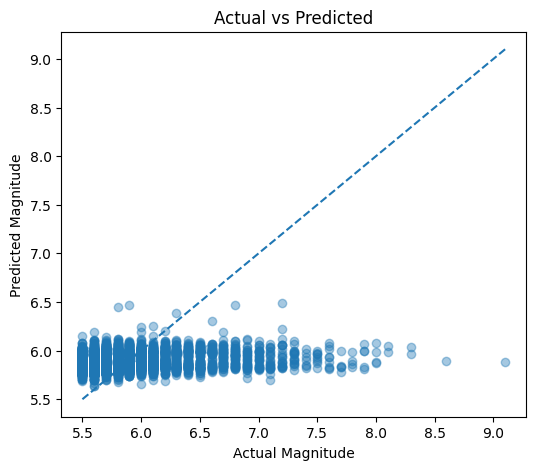

In [18]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, gbr_pred, alpha=0.4)

low = min(y_test.min(), gbr_pred.min())
high = max(y_test.max(), gbr_pred.max())

plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual Magnitude")
plt.ylabel("Predicted Magnitude")
plt.title("Actual vs Predicted")
plt.show()


**Feature Importance**

This shows which input features were most useful for the Gradient Boosting model


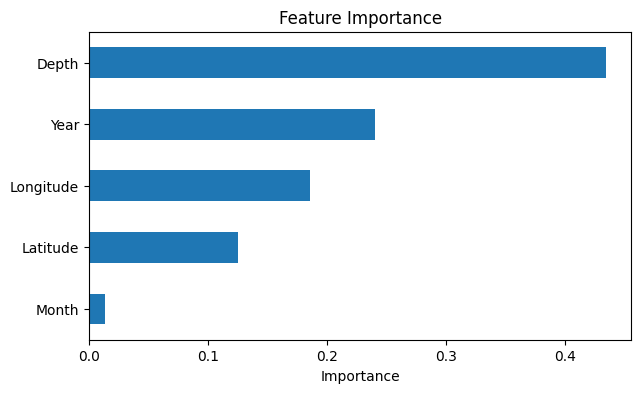

In [19]:
importance = pd.Series(
    gbr.feature_importances_,
    index=features
).sort_values()

importance.plot(kind="barh", figsize=(7, 4))
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()


**Conclusion**

In this project, we used four Regression models to estimate earthquake magnitude using historical data: **Linear Regression**, **Decision Tree**, **Random Forest**, and **Gradient Boosting**.

We compared the models using **MAE, RMSE, and R²**.

**Random Forest** performed slightly better than the other models, with an MAE of **0.300** and an R² score of **0.062**.

However, the low R² score shows that the models have limited prediction performance. More geological and seismic data would be needed for more reliable predictions.

This project demonstrates a simple Machine Learning workflow, from data analysis to model evaluation.